Cluster Centers (HSV):
  Cluster 0: H=76.4, S=56.0, V=62.0
  Cluster 1: H=82.9, S=98.7, V=54.1
  Cluster 2: H=34.5, S=42.9, V=182.8
  Cluster 3: H=38.5, S=31.2, V=84.8

Terrain Assignment:
  Cluster 1: Water | Cost=10
  Cluster 0: Vegetation | Cost=8
  Cluster 3: Rocky | Cost=4
  Cluster 2: Open Land | Cost=1


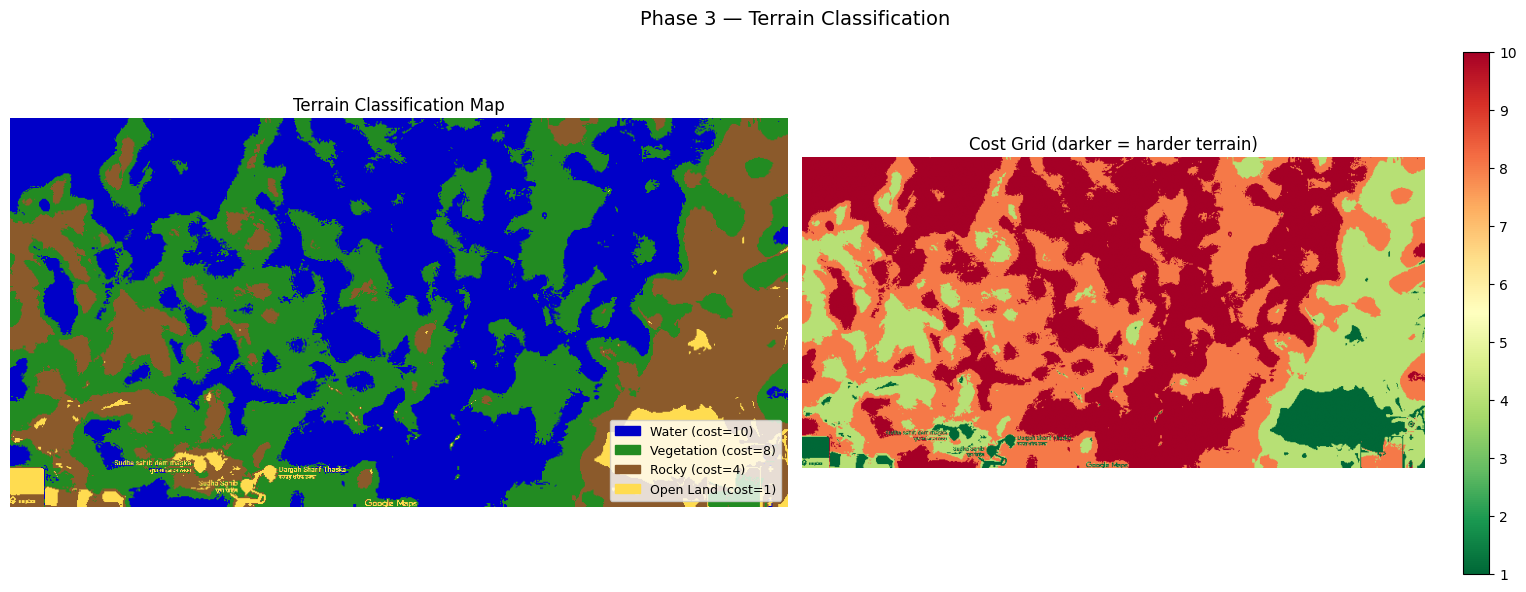

Cost grid and terrain map saved!


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans

# ── LOAD PREPROCESSED IMAGE ─────────────────────────────
image_hsv = np.load(r"C:\Users\vinay\OneDrive\Desktop\CODING\path project\input\preprocessed.npy")

# ── STEP 1: RESHAPE FOR K-MEANS ─────────────────────────
h, w, c = image_hsv.shape
pixels = image_hsv.reshape(-1, 3).astype(np.float32)

# ── STEP 2: K-MEANS CLUSTERING ──────────────────────────
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(pixels)
labels = kmeans.labels_.reshape(h, w)
centers = kmeans.cluster_centers_

print("Cluster Centers (HSV):")
for i, center in enumerate(centers):
    print(f"  Cluster {i}: H={center[0]:.1f}, S={center[1]:.1f}, V={center[2]:.1f}")

# ── STEP 3: FORCE ASSIGN ALL 4 CLUSTERS ─────────────────
# Sort clusters by Value (brightness): darkest=water, then vegetation, rocky, brightest=open
brightness_order = np.argsort(centers[:, 2])  # sort by V channel

terrain_list = [
    ('Dark Forest',      10, [0, 0, 200]),
    ('Vegetation',  8, [34, 139, 34]),
    ('Rocky',       4, [139, 90, 43]),
    ('Open Land',   1, [255, 220, 80]),
]

# Map cluster index → terrain
cluster_to_terrain = {}
for rank, cluster_idx in enumerate(brightness_order):
    cluster_to_terrain[cluster_idx] = terrain_list[rank]

print("\nTerrain Assignment:")
for cluster_idx, (name, cost, color) in cluster_to_terrain.items():
    print(f"  Cluster {cluster_idx}: {name} | Cost={cost}")

# ── STEP 4: BUILD COST GRID ──────────────────────────────
cost_grid = np.zeros((h, w), dtype=np.float32)
color_map = np.zeros((h, w, 3), dtype=np.uint8)

for cluster_idx, (name, cost, color) in cluster_to_terrain.items():
    mask = labels == cluster_idx
    cost_grid[mask] = cost
    color_map[mask] = color

# ── DISPLAY ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(color_map)
axes[0].set_title("Terrain Classification Map")
axes[0].axis('off')

patches = [mpatches.Patch(color=np.array(color)/255, label=f"{name} (cost={cost})")
           for name, cost, color in terrain_list]
axes[0].legend(handles=patches, loc='lower right', fontsize=9)

im = axes[1].imshow(cost_grid, cmap='RdYlGn_r')
axes[1].set_title("Cost Grid (darker = harder terrain)")
axes[1].axis('off')
plt.colorbar(im, ax=axes[1])

plt.suptitle("Phase 3 — Terrain Classification", fontsize=14)
plt.tight_layout()
plt.show()

# ── SAVE ─────────────────────────────────────────────────
np.save(r"C:\Users\vinay\OneDrive\Desktop\CODING\path project\input\cost_grid.npy", cost_grid)
np.save(r"C:\Users\vinay\OneDrive\Desktop\CODING\path project\input\terrain_map.npy", color_map)
print("Cost grid and terrain map saved!")